# Petrophys: first plot, then interpretation

Start with a bundled LAS. No formation table, lithology file, Rw, or mineral assumptions are needed to view existing measurements.

This notebook teaches three distinct tasks: **read**, **plot**, and optionally **interpret**. It uses only public library APIs. Run the cells from the top in a Python kernel where Petrophys is installed; [lesson 00](part_a_foundations/00_orientation_and_setup.ipynb) shows how to set one up.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()

## 1. Plot a LAS in a few lines

The depth window is specific to the bundled 30/6-5 well, in metres. For another well, omit it initially or choose a window in that well's depth units.

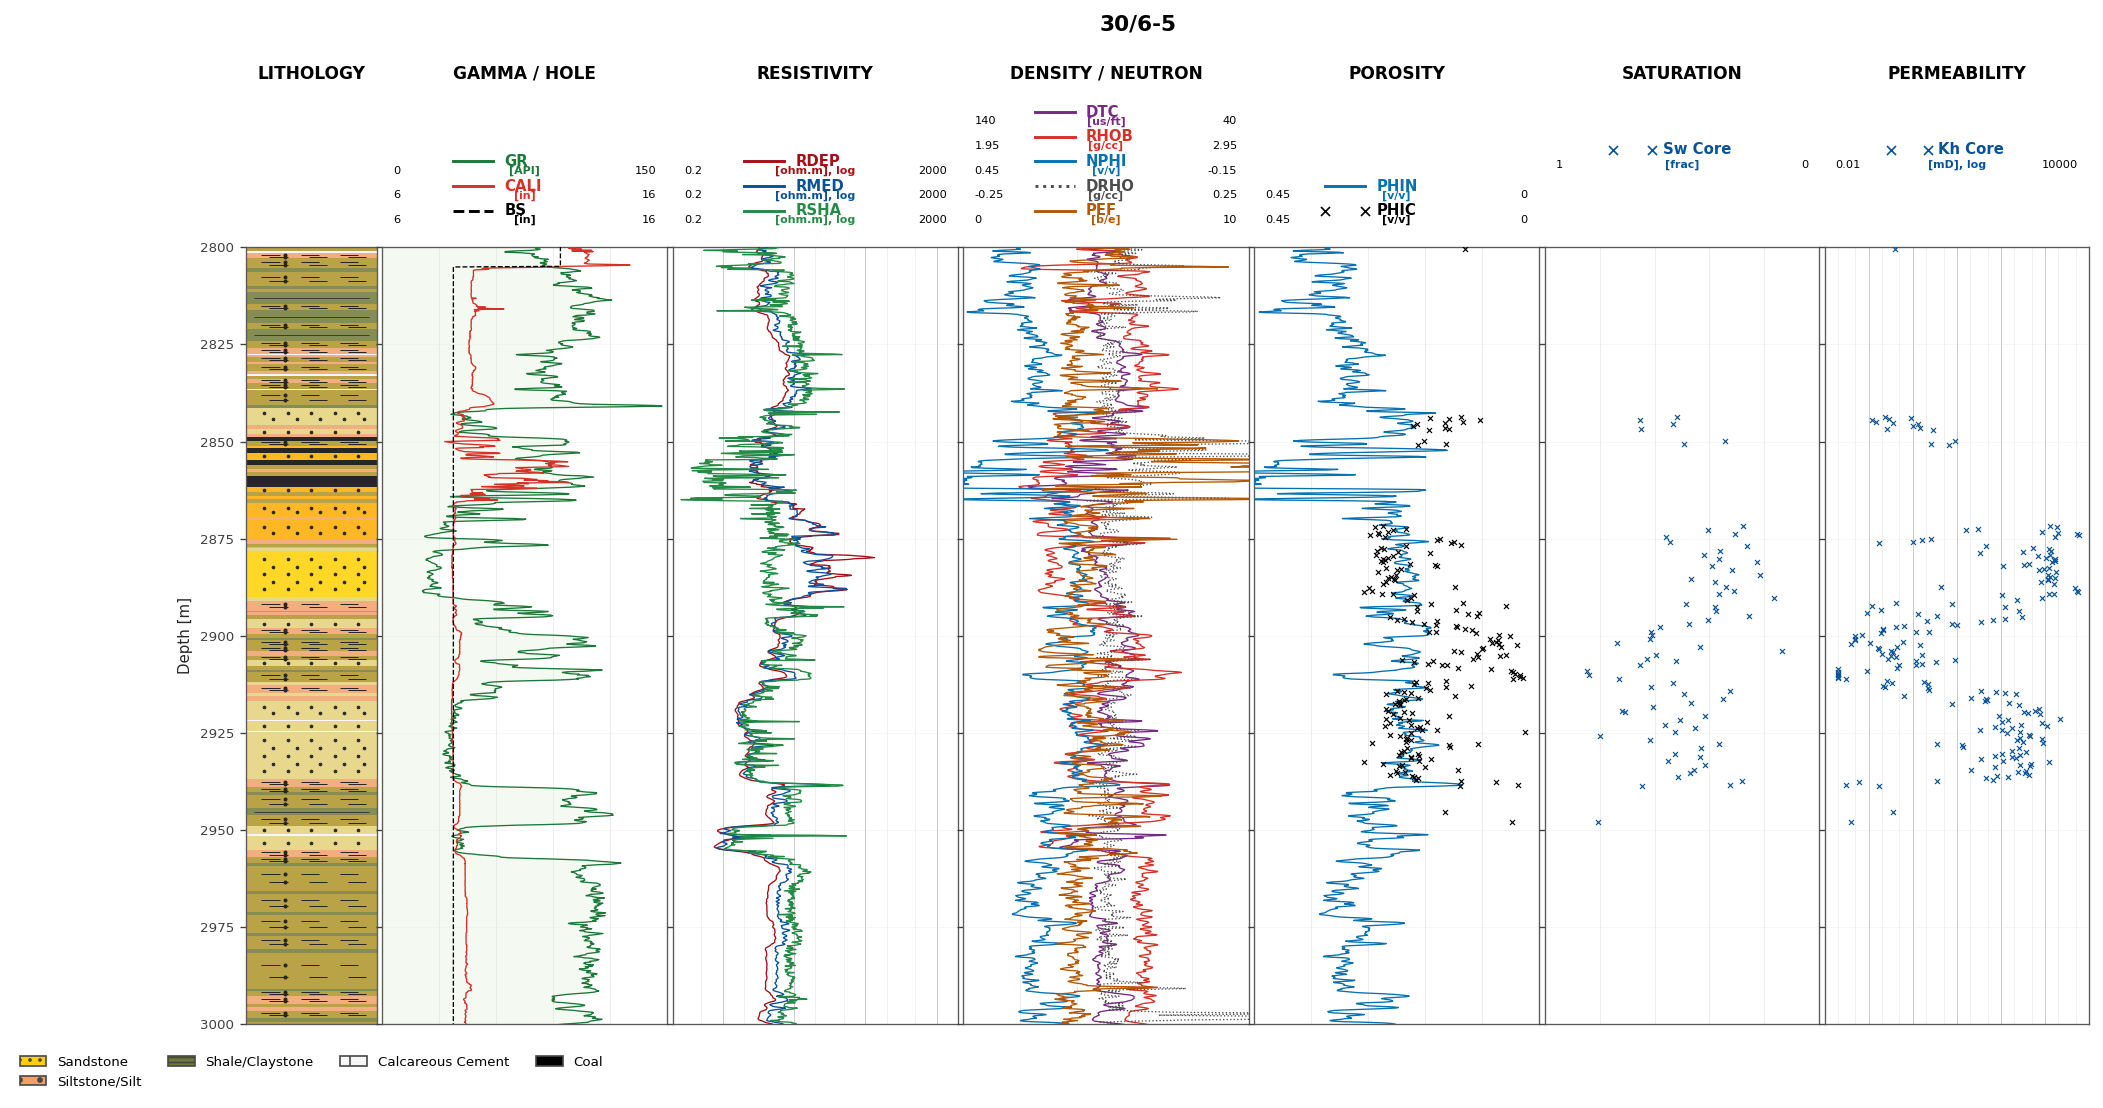

In [2]:
import petrophys as pp
well = pp.read(pp.sample("30_6-5"))
viewer = pp.plot(well, depth_range=(2800, 3000), figsize=(16, 9))
viewer.show()
viewer.close()

The viewer shows existing logs and core measurements; it does not calculate a missing `SW` curve. The **Sw Core** points are measured core saturation, not a continuous log-derived result.

**About the two `UserWarning` messages above.** The bundled LAS labels its core saturation curves `SWC` and `SOC` as fractions (`frac`), but their values are percentages. Petrophys infers this, divides by 100 on a display copy, and warns you to check the source units. The source well is unchanged by plotting. The next cell hides only this already-explained message so later outputs stay readable; every other warning still appears.

In [3]:
import warnings

# Explained above: SWC/SOC hold percentages despite a 'frac' unit label.
# Hide only that message; all other warnings remain visible.
warnings.filterwarnings(
    "ignore", message=r"(SWC|SOC): inferred percent core saturation", category=UserWarning,
)

raw_curves = tuple(well.curves)
print(well.name, well.top, well.bottom, well.depth_unit)
print("Existing SW curve:", well.get("SW") is not None)
print("Plot warnings:", viewer.warnings)
print("Omitted tracks:", viewer.diagnostics["omitted_tracks"])

30/6-5 176.60999 3556.08032 m
Existing SW curve: False
Plot warnings: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]
Omitted tracks: []


## 2. Add optional formations or lithology

Either file may be omitted. The bundled companion files are example interpretations for this well. External intervals attached with `pp.read` are used by both plotting and subsequent interpretation. No manual numeric rock coding is required.

For your own files, use [the own-data tutorial](own_data.ipynb) and the downloadable [input templates](../docs/input_templates.md). Do not use template example rows as picks for your well.

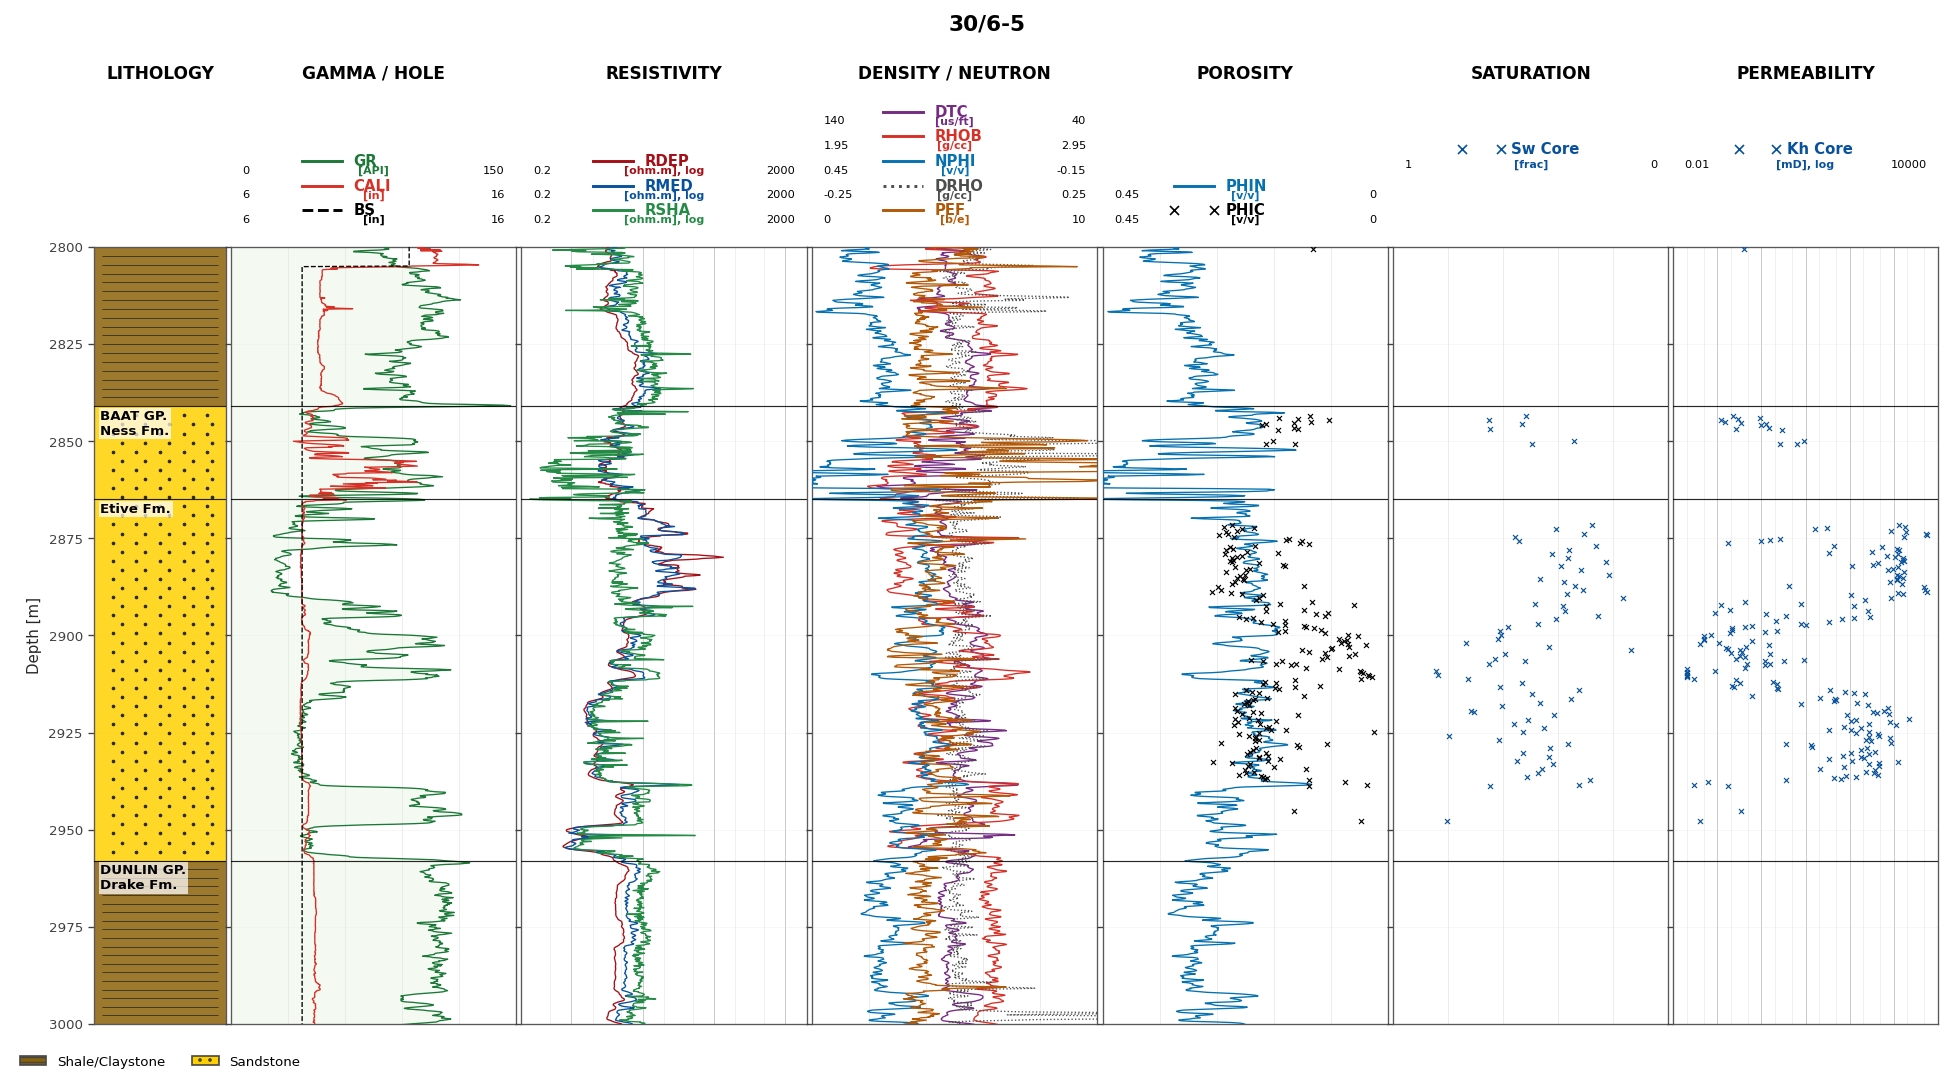

Lithology source: external
Formation rows: 20
Suppressed labels: []


In [4]:
context_well = pp.read(
    pp.sample("30_6-5"),
    formations=pp.sample("formations_30_6-5"),
    lithology=pp.sample("lithology_30_6-5"),
)
context_viewer = pp.plot(context_well, depth_range=(2800, 3000), figsize=(16, 9))
context_viewer.show()
context_viewer.close()
print("Lithology source:", context_viewer.diagnostics["lithology_source"])
print("Formation rows:", context_viewer.diagnostics["formations"]["accepted_rows"])
print("Suppressed labels:", context_viewer.diagnostics["suppressed_formation_labels"])

## 3. Interpret, separately from plotting

Below, `Rw = 0.07 ohm.m` **measured at 230 degF** (`rw_meas_temp_f=230`) is an illustrative teaching assumption for this well, not a recommendation for another well. Always state the temperature at which Rw was measured: without `rw_meas_temp_f`, Petrophys assumes 75 degF, which changes the temperature-corrected Rw and therefore water saturation substantially. Fluid properties, rock models and cutoffs must also be justified for your application. No default Rw is silently introduced when supported inputs are unavailable.

This run deliberately uses the LAS-only `well`. External geology is not required. Embedded vendor lithology may be used when available; without it, supported logs can drive mineral inversion.

`pp.interpret` works on a copy of the well. The lower-level `pp.run_dynamic_workflow` adds curves to the well you pass in.

In [5]:
result = pp.interpret(well, rw=0.07, rw_meas_temp_f=230)
result.raise_for_errors()
assert result.well is not well
assert tuple(well.curves) == raw_curves
print("Status:", result.status)
print("Skipped steps:")
for step, reason in result.specific_steps_skipped.items():
    print(f"  {step}: {reason}")
print("Warnings:")
for message in result.warnings:
    print("  -", message)

Status: interpreted
Skipped steps:
  normalization: standardize_input=False
  spectral_gamma: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
  elemental_spectroscopy: Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
  hc_correction: apply_hc_correction=False (hydrocarbon correction is opt-in)
  porosity_refinement: Not run by the interpretation workflow; porosity is computed once in the porosity step
Warnings:


## 4. Inspect decisions, not just success

A successful run can still have skipped calculations. Read the selected methods, assumptions and missing inputs before using its outputs. `result.to_dataframe()` has one row per executed step; its **Decisions** column records why each method and parameter was chosen. Use `raise_on_error=True` during interpretation when you want the original exception for debugging.

In [6]:
trace = result.to_dataframe()
trace[["Step", "Status", "Method"]]

,Step,Status,Method
0,input_context,OK,validated_geology_selection
1,temperature,OK,linear_gradient_from_BHT
2,bad_hole,OK,caliper_drho_flags
3,vclay,OK,linear
4,rcl,OK,lithology_shale_median_rt
5,rmf,OK,las_metadata_assumed_reference_temperature
6,porosity,OK,component_based
7,lithology,OK,canonical_multi_mineral_solver
8,core_correction,OK,same_well_core_correction
9,rw,OK,user_provided_temperature_profile_corrected


In [7]:
decisions = trace.set_index("Step")["Decisions"]
for step in ("input_context", "rw", "saturation"):
    print(step)
    for item in decisions[step].split(" | "):
        print("   -", item)

input_context
   - Selected vendor lithology; alternate sources were retained
rw
   - Rw corrected from 0.0700 ohm.m @ 230F along the temperature profile
saturation
   - Model selected: archie+indonesia+dual_water
   - Canonical Indonesia and Dual Water equations used
   - Auto-routing: depth-by-depth model selection based on VCLAY and lithology
   - Depth routing counts: archie=19397, indonesia=2602, dual_water=177
   - Archie coefficients from lithology (ground_truth_lithology_geolink)
   - No finite source SW input was available; SW is Archie-computed where inputs are finite
   - Dual Water phi_cl = 0.070 from lithology_shale_average_phit_nd
   - Rw range = 0.0624 to 0.1967, Rcl = 2.9059999999999997
   - SXO from invaded-zone Archie where RSHA/RXO/RESS and RMF were finite; SXO = SW^(1/5) elsewhere (archie_rxo_rmf=22079, fifth_root_quicklook=92)
   - Sw range: 0.000 - 1.000


### Summarize the reservoir, not the whole well

This log starts at about 177 m, in shallow and poorly consolidated sediments. Their high apparent porosity can pass porosity and saturation cutoffs, so whole-well averages and totals are misleading. Summarize the interval you are evaluating instead. Here that is the Brent Group reservoir, 2841-2958 m (Ness and Etive formations).

`result.summary(top=..., bottom=...)` returns compact statistics and net thicknesses for that window. When formations are attached with `pp.read(..., formations=...)`, `result.formation_summary(rank="formation")` gives the same numbers per formation (see [Your Own Data](own_data.ipynb)).

In [8]:
import pandas as pd

brent = result.summary(top=2841, bottom=2958)
net = brent["net_thickness"]
print("Interval:", brent["summary_interval"])
print(f"Net reservoir {net['net_res']:.1f} {net['depth_unit']}, "
      f"net pay {net['net_pay']:.1f} {net['depth_unit']}")
stats = pd.DataFrame(brent["key_results"]).T
stats[["p10", "median", "p90"]].astype(float).round(3).assign(unit=stats["unit"])

Interval: {'top': 2841, 'bottom': 2958, 'depth_unit': 'm'}
Net reservoir 82.7 m, net pay 40.1 m


,p10,median,p90,unit
VCL,0.000,0.075,0.398,v/v
PHIT,0.102,0.195,0.251,v/v
PHIE,0.081,0.191,0.249,v/v
SW,0.216,0.628,1.000,v/v
PERM,7.843,249.105,711.932,mD


## 5. Plot the interpreted result

`result.plot` and `pp.plot` return the same `LogViewer` type, with `show`, `save`, `close`, `fig`, `axes`, and `diagnostics`. A computed saturation curve can now appear alongside the core observations.

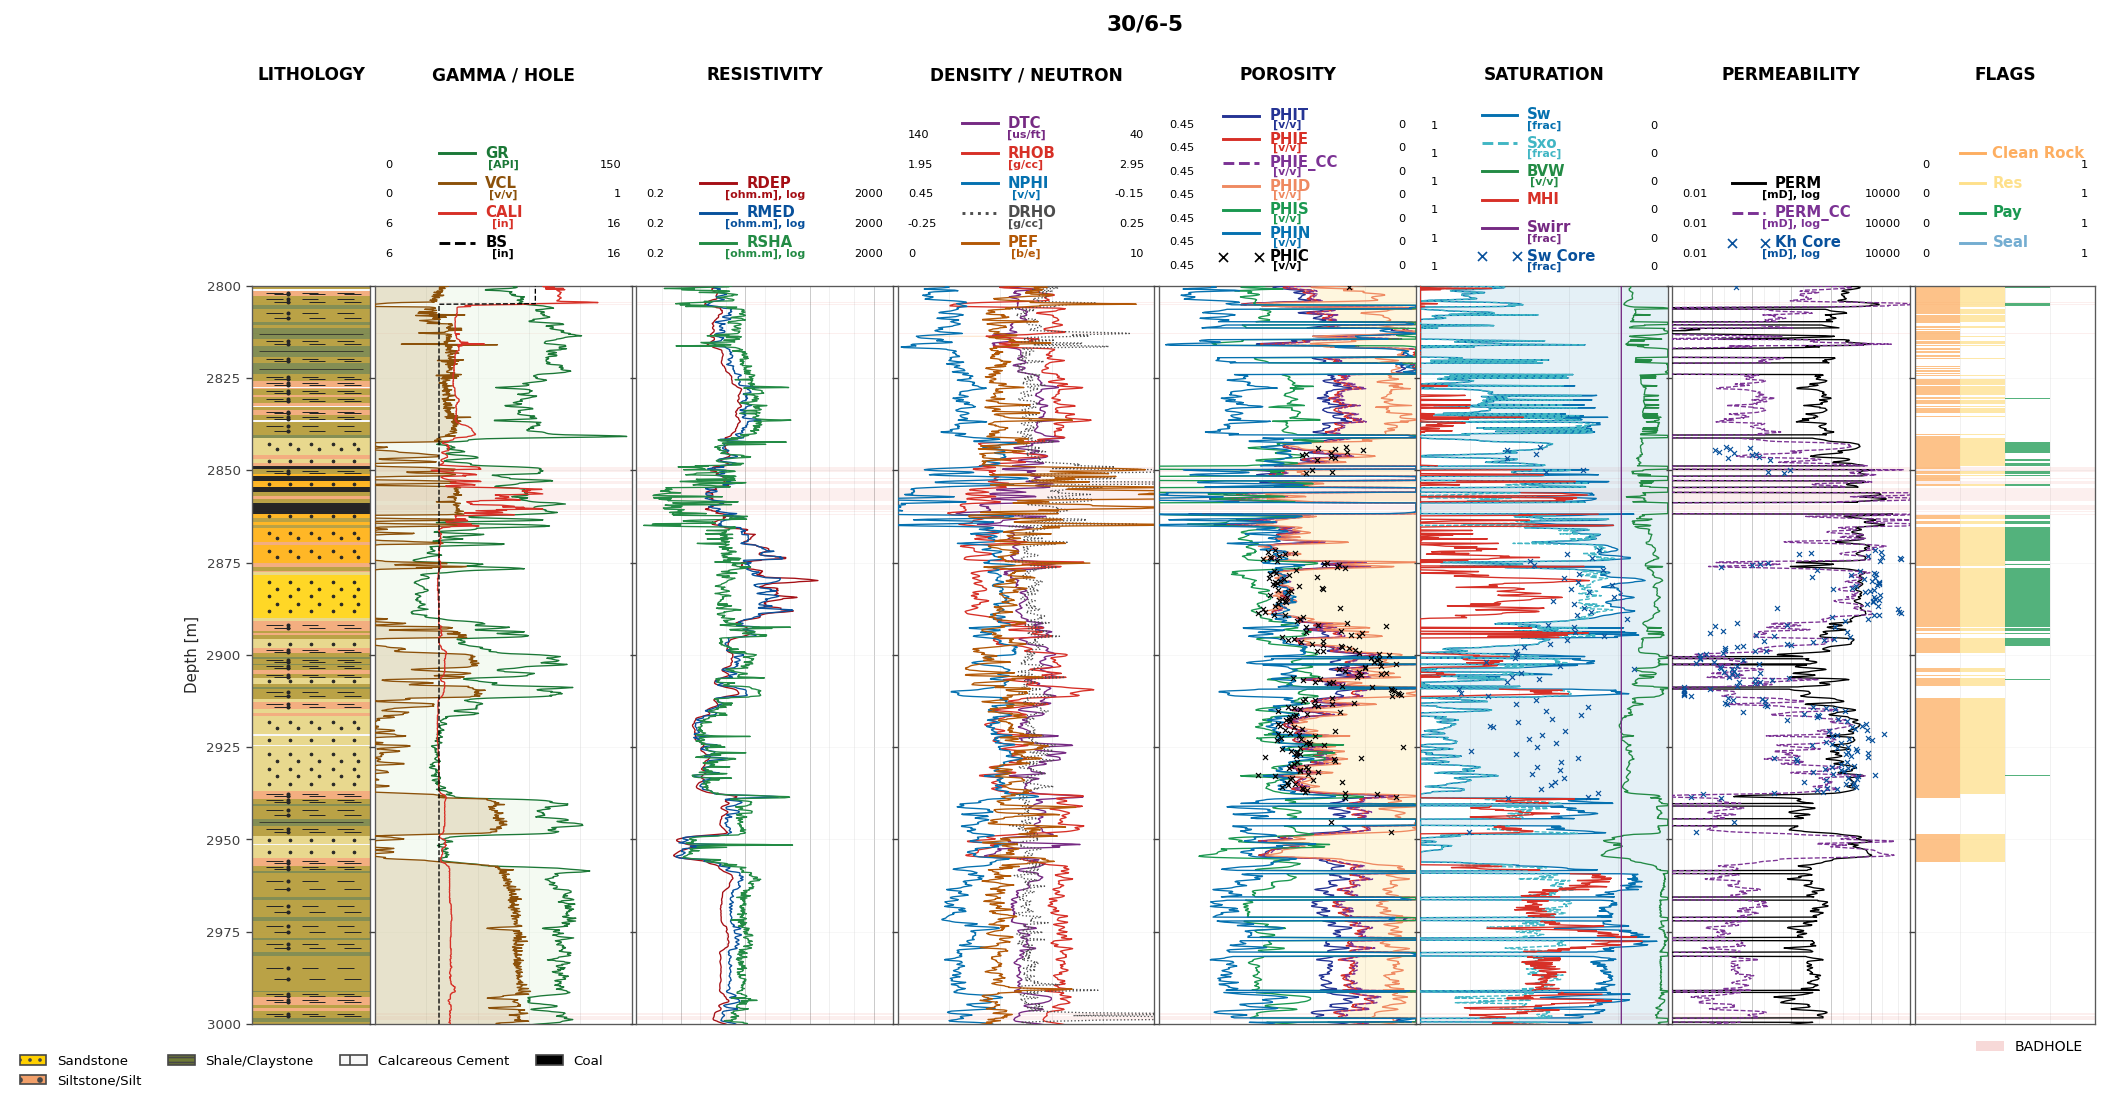

In [9]:
interpreted_viewer = result.plot(depth_range=(2800, 3000), figsize=(16, 9))
interpreted_viewer.show()
interpreted_viewer.close()

## Use your own data or go deeper

- Replace `pp.sample("30_6-5")` with your LAS path. Plot it before adding interpretation assumptions.
- Follow [Your Own Data](own_data.ipynb) for CSV/TSV logs, geology templates, Excel sheets, column mappings, depth checks and per-formation summaries.
- Work through the calculations one quantity at a time, starting with [lesson 00](part_a_foundations/00_orientation_and_setup.ipynb).
- See [lesson 05](part_a_foundations/05_lithology_and_mineral_solver.ipynb) for the mineral solver without external geology.
- See [lesson 10](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) for detailed configuration, source selection and traces.
- See [lesson 11](part_b_advanced/11_formation_and_interval_analysis.ipynb) for top-only picks, explicit bottoms and union-based totals.
- See [lesson 17](part_b_advanced/17_visualization_masterclass.ipynb) for track selection and advanced plot composition.
- NMR uses a specialist interface: [lesson 14](part_b_advanced/14_nmr_petrophysics.ipynb).